# 12 · Final evaluation & business decisions

**The final exam.** Refit the chosen models on everything whose labels were known by June 2011, score the **test cutoff (2011-06-09 → next 6 months to 2011-12-09) once**,
and turn the results into decisions: retention targeting, CAC caps, revenue forecasting.

### Pre-registration: written *before* scoring the test set
Once we've seen test results, any change we make turns the test set into a second validation set. So the plan is fixed here:

| Item | Fixed choice (from notebooks 03–08) |
|---|---|
| Training data | all 12 monthly cutoffs of 2010 (labels matured by the test cutoff) |
| Buy model | logistic regression, C = 1, without the basket features |
| Spend model | two-part: P(buy) × LightGBM-on-log spend\|buy (buyers only, smearing on buyers) |
| Level calibration | shift P(buy) and scale spend\|buy so the final model matches the **same season one year earlier** (June 2010 cutoff), on its own predictions |
| Headline metrics | AUC (buy); Spearman, Gini, top-10% capture (spend), with paired bootstrap CIs vs. the naive baseline |
| Reported for context only | runner-up models (tuned LightGBM, Tweedie): **not** used to re-select |

### 🧠 Predict first
1. Will the test AUC be higher or lower than validation's (0.78 in December)? Why might it differ?
2. Validation showed predictions **too high** in the off-season. The test window contains Q4. Will the test totals be too high or too low?
3. If one of the runner-ups scores better on test, should we switch?

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import spearmanr
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss

sys.path.insert(0, str(Path.cwd().parent))
from src.clean import CLEAN_PARQUET, RETURNS_PARQUET
from src.split import FINAL_CUTOFFS, TEST_CUTOFF, MARGIN, build_snapshot
from src.features import CATALOG, build_feature_table
from src.preprocess import MODEL_INPUTS, NUM_FEATURES
from src.evaluate import regression_metrics, decile_table
from src.models import make_logreg, make_lgbm_log, make_lgbm_classifier, make_lgbm_tweedie

pd.set_option("display.width", 170)
warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
np.random.seed(SEED)
PROCESSED = Path(CLEAN_PARQUET).parent

## 1. Build the test set and refit on all of 2010
This is the first and only time the test window's purchases are used. The snapshot builder needs an explicit `allow_test=True`, the guard from notebook 03.

In [2]:
purchases = pd.read_parquet(CLEAN_PARQUET)  # full data, including the test window
returns = pd.read_parquet(RETURNS_PARQUET)
test = build_feature_table(purchases, returns, build_snapshot(purchases, TEST_CUTOFF, allow_test=True))

table = pd.read_parquet(PROCESSED / "features.parquet")
train = table[table["cutoff"].isin(FINAL_CUTOFFS)]
june10 = train[train["cutoff"] == pd.Timestamp("2010-06-09")]

pd.DataFrame({
    "rows": [len(train), len(june10), len(test)],
    "buy rate": [train["y_buy"].mean(), june10["y_buy"].mean(), test["y_buy"].mean()],
    "mean 6m spend £": [train["y_spend"].mean(), june10["y_spend"].mean(), test["y_spend"].mean()],
    "share silent > 180 days": [(train["recency_days"] > 180).mean(), (june10["recency_days"] > 180).mean(), (test["recency_days"] > 180).mean()],
    "max tenure (days)": [train["tenure_days"].max(), june10["tenure_days"].max(), test["tenure_days"].max()],
}, index=["final training (12 cutoffs)", "June 2010 (same season)", "TEST June 2011"]).round(3)

,rows,buy rate,mean 6m spend £,share silent > 180 days,max tenure (days)
final training (12 cutoffs),33254,0.637,1108.007,0.104,373
June 2010 (same season),2772,0.714,1352.572,0.050,190
TEST June 2011,4942,0.520,874.124,0.466,555


**Takeaway, before any model:** the test pool looks different from anything in training.
- **47% of test customers have been silent for more than 180 days** (vs. 5% at the June 2010 cutoff): two years of accumulated dormant customers.
- **Tenure reaches 555 days**, beyond the training maximum of 373. Notebook 04's skew risk is now real.
- The buy rate (52%) is far below June 2010's (71%), despite the same season. The dormant pool dominates.

In [3]:
family = CATALOG.set_index("feature")["family"]
BASKET = tuple(c for c in NUM_FEATURES if family[c] == "Basket")

buy_model = make_logreg(exclude=BASKET).fit(train[MODEL_INPUTS], train["y_buy"])
buyers = train[train["y_spend"] > 0]
spend_model = make_lgbm_log().fit(buyers[MODEL_INPUTS], buyers["y_spend"])

# Pre-registered level calibration, fit on the same season one year earlier (June 2010 cutoff)
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
sigmoid = lambda z: 1 / (1 + np.exp(-z))
p_j = buy_model.predict_proba(june10[MODEL_INPUTS])[:, 1]
s_j = spend_model.predict(june10[MODEL_INPUTS])
DELTA = brentq(lambda d: sigmoid(logit(p_j) + d).mean() - june10["y_buy"].mean(), -5, 5)
is_buyer_j = june10["y_spend"].values > 0
K = june10["y_spend"].values[is_buyer_j].sum() / s_j[is_buyer_j].sum()
print(f"June 2010: actual buy rate {june10['y_buy'].mean():.3f} vs model {p_j.mean():.3f} → log-odds shift Δ = {DELTA:+.3f}")
print(f"June 2010: actual spend per buyer vs model spend|buy → scale k = {K:.3f}")

t = test.copy()
t["p"] = buy_model.predict_proba(t[MODEL_INPUTS])[:, 1]
t["p_cal"] = sigmoid(logit(t["p"]) + DELTA)
t["s"] = spend_model.predict(t[MODEL_INPUTS])
t["e"] = t["p"] * t["s"]
t["e_cal"] = t["p_cal"] * t["s"] * K

June 2010: actual buy rate 0.714 vs model 0.654 → log-odds shift Δ = +0.317
June 2010: actual spend per buyer vs model spend|buy → scale k = 1.058


## 2. Test results: will they buy?

In [4]:
def buy_metrics(y, p, prob=True):
    out = {"AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}
    if prob:
        out |= {"mean P(buy)": np.mean(p), "log loss": log_loss(y, p), "Brier": brier_score_loss(y, p)}
    return out


y = t["y_buy"]
print(f"Actual test buy rate: {y.mean():.3f}")
pd.DataFrame({
    "naive score (spend_180d)": buy_metrics(y, t["spend_180d"], prob=False),
    "logistic regression (raw)": buy_metrics(y, t["p"]),
    "logistic regression (June-2010 calibrated)": buy_metrics(y, t["p_cal"]),
}).T.round(4)

Actual test buy rate: 0.520


,AUC,PR-AUC,mean P(buy),log loss,Brier
naive score (spend_180d),0.7516,0.7657,NaN,NaN,NaN
logistic regression (raw),0.7922,0.8242,0.4947,0.5457,0.1851
logistic regression (June-2010 calibrated),0.7922,0.8242,0.5503,0.5465,0.1854


In [5]:
def paired_ci(y, a, b, fn, n_boot=1000):
    y, a, b = np.asarray(y), np.asarray(a), np.asarray(b)
    rng = np.random.default_rng(SEED)
    d = [fn(y[i], a[i]) - fn(y[i], b[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))]
    return fn(y, a) - fn(y, b), *np.quantile(d, [0.025, 0.975])


def single_ci(y, a, fn, n_boot=1000):
    y, a = np.asarray(y), np.asarray(a)
    rng = np.random.default_rng(SEED)
    s = [fn(y[i], a[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))]
    return fn(y, a), *np.quantile(s, [0.025, 0.975])


est, lo, hi = single_ci(y, t["p"], roc_auc_score)
print(f"Test AUC, logistic regression: {est:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")
d, lo, hi = paired_ci(y, t["p"], t["spend_180d"], roc_auc_score)
print(f"Test AUC, logistic regression − naive: {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

Test AUC, logistic regression: 0.7922  95% CI [0.7799, 0.8048]


Test AUC, logistic regression − naive: +0.0406  95% CI [+0.0326, +0.0482]


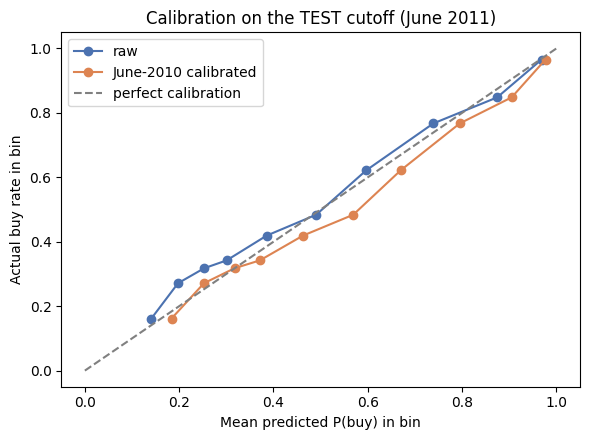

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for col, label, color in [("p", "raw", "#4C72B0"), ("p_cal", "June-2010 calibrated", "#DD8452")]:
    fp, mp = calibration_curve(y, t[col], n_bins=10, strategy="quantile")
    ax.plot(mp, fp, marker="o", label=label, color=color)
ax.plot([0, 1], [0, 1], ls="--", color="grey", label="perfect calibration")
ax.set_title("Calibration on the TEST cutoff (June 2011)")
ax.set_xlabel("Mean predicted P(buy) in bin")
ax.set_ylabel("Actual buy rate in bin")
ax.legend()
plt.tight_layout()
plt.show()

**Takeaways:**
- **Ranking holds up, and improves:** test AUC ≈ 0.79, clearly above the naive score (paired CI excludes zero). It's slightly *above* validation's 0.78. Plausible reasons: more training data (12 cutoffs instead of 6),
  and an easier test pool (many long-dormant customers are easy to rank low).
- **The raw probabilities are already close to the truth** (mean ≈ 0.49 vs. 0.52 actual), unlike validation's 0.76 vs. 0.46. The final refit trained on **both seasons** (Jan–Dec cutoffs),
  and the features capture dormancy, so the model's level is roughly right out of the box.
- **The pre-registered June-2010 correction didn't help** (it nudged the mean to 0.55 and left log loss and Brier essentially unchanged).
  Why: it assumes the *pool* is like last June's, but last June only 5% of customers were long-dormant vs. 47% now. The features already account for that, so a pool-level shift partly double-counts.
  **Lesson: a calibration fix has to match the cause of the miscalibration.** In validation the cause was season-only training data; in the final refit that cause was mostly removed.
  We report it as pre-registered, and we don't quietly drop it after seeing the test.

## 3. Test results: how much will they spend?

In [7]:
ys = t["y_spend"]
spend_tbl = pd.DataFrame({
    "naive (last 6m)": regression_metrics(ys, t["spend_180d"]),
    "two-part (raw)": regression_metrics(ys, t["e"]),
    "two-part (June-2010 calibrated)": regression_metrics(ys, t["e_cal"]),
}).T[["spearman", "gini", "top10_capture", "total_pct_error", "mae", "rmse"]]
display(spend_tbl.round(3))

rho = lambda a, b: spearmanr(a, b).correlation
gin = lambda a, b: regression_metrics(a, b)["gini"]
top = lambda a, b: regression_metrics(a, b)["top10_capture"]
for name, fn in [("Spearman", rho), ("Gini", gin), ("Top-10% capture", top)]:
    d, lo, hi = paired_ci(ys, t["e"], t["spend_180d"], fn, n_boot=500)
    print(f"Test {name:<16} two-part − naive: {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

,spearman,gini,top10_capture,total_pct_error,mae,rmse
naive (last 6m),0.570,0.814,0.616,-0.295,560.457,2726.761
two-part (raw),0.606,0.863,0.626,-0.345,590.833,3191.113
two-part (June-2010 calibrated),0.602,0.863,0.625,-0.267,594.062,3109.434


Test Spearman         two-part − naive: +0.0363  95% CI [+0.0198, +0.0526]


Test Gini             two-part − naive: +0.0494  95% CI [+0.0345, +0.0729]


Test Top-10% capture  two-part − naive: +0.0104  95% CI [+0.0020, +0.0199]


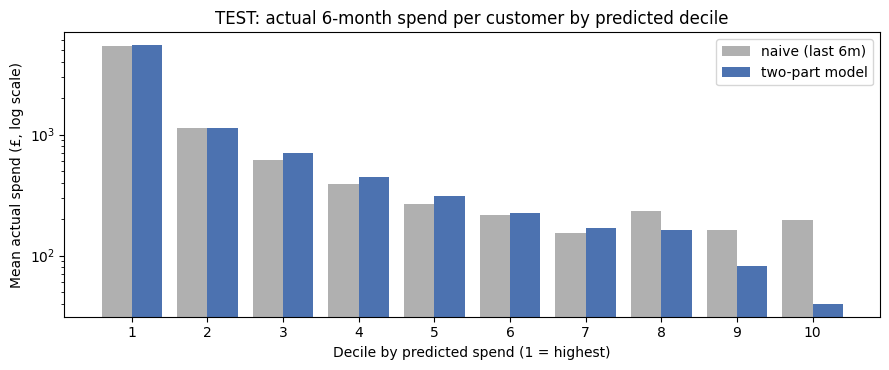

,naive actual £,model actual £,model lift,model share of revenue
decile,,,,
1,5379.37,5470.03,6.26,0.63
2,1127.02,1132.61,1.30,0.13
3,613.58,699.66,0.80,0.08
4,390.01,441.64,0.51,0.05
5,266.25,312.36,0.36,0.04
6,214.21,222.78,0.25,0.03
7,152.68,169.64,0.19,0.02
8,231.14,162.72,0.19,0.02
9,163.56,82.29,0.09,0.01


In [8]:
dt_m, dt_n = decile_table(ys, t["e"]), decile_table(ys, t["spend_180d"])
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(1, 11)
ax.bar(x - 0.2, dt_n["mean_actual"], width=0.4, label="naive (last 6m)", color="#B0B0B0")
ax.bar(x + 0.2, dt_m["mean_actual"], width=0.4, label="two-part model", color="#4C72B0")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_title("TEST: actual 6-month spend per customer by predicted decile")
ax.set_xlabel("Decile by predicted spend (1 = highest)")
ax.set_ylabel("Mean actual spend (£, log scale)")
ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame({"naive actual £": dt_n["mean_actual"], "model actual £": dt_m["mean_actual"],
              "model lift": dt_m["lift"], "model share of revenue": dt_m["share_of_actual"]}).round(2)

**Takeaways:**
- **The two-part model beats "last 6 months" on Spearman (+0.036) and Gini (+0.049), CIs excluding zero**, a larger margin than in validation.
  Top-10% capture also improves slightly (+0.010, CI excludes zero), unlike in validation: the biggest spenders are still mostly easy for the naive rule.
- **The decile pattern repeats validation:** similar at the top, cleaner at the bottom. Customers the model ranks last really do spend the least, while the naive rule's bottom deciles still contain returning customers.
- **Level: now *under*-predicting (about −35% raw, −27% calibrated).** Validation over-predicted the off-season; the test window contains the Q4 peak, and a model trained across all months predicts an *average-season* level.
  The June-2010 scale (k ≈ 1.06) only fixes a little.
  **Lesson for production:** don't use a customer-level model's sum as the revenue forecast. Forecast the **total** with a seasonal time-series model, and use the customer model to **allocate** it across customers.

## 4. Runner-ups, reported for context (not to re-select)

In [9]:
lgbm_params = dict(learning_rate=0.0152, n_estimators=200, num_leaves=3, min_child_samples=230,
                   reg_lambda=5.19, colsample_bytree=0.70, subsample=0.84)  # tuned in notebook 08
lgbm = make_lgbm_classifier(**lgbm_params).fit(train[MODEL_INPUTS], train["y_buy"])
p_lgbm = lgbm.predict_proba(t[MODEL_INPUTS])[:, 1]
d, lo, hi = paired_ci(y, p_lgbm, t["p"], roc_auc_score)
print(f"Test AUC: tuned LightGBM {roc_auc_score(y, p_lgbm):.4f} vs logistic regression {roc_auc_score(y, t['p']):.4f} "
      f"→ diff {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

tweedie = make_lgbm_tweedie().fit(train[MODEL_INPUTS], train["y_spend"])
d, lo, hi = paired_ci(ys, tweedie.predict(t[MODEL_INPUTS]), t["e"], rho, n_boot=500)
print(f"Test Spearman: Tweedie − two-part = {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

Test AUC: tuned LightGBM 0.7993 vs logistic regression 0.7922 → diff +0.0071  95% CI [+0.0021, +0.0126]


Test Spearman: Tweedie − two-part = -0.0145  95% CI [-0.0210, -0.0078]


**Takeaway:** the tuned LightGBM beats our chosen logistic regression on test: **+0.007 AUC, with a CI that excludes zero.** Small, but real. Do we switch? **No.**
- The decision was made on validation, before seeing test. Switching now means choosing *with* the test set, which makes it a second validation set; the reported score would become optimistic, and we'd have no honest estimate left.
- **What we *do* take from it:** with 12 training cutoffs (twice the data, both seasons), the GBM overtook the linear model. That fits notebook 08's learning curves, where the GBM gained more from data.
  It's the leading hypothesis for the **next** model iteration, to be confirmed on **new** data (e.g. the next cutoff).
- The cost of our choice is small: 0.007 AUC, for a model that's simpler to explain, monitor and recalibrate.
- Tweedie vs. two-part on spend: the two-part model holds its lead (Tweedie is significantly worse on Spearman).

**Interview line:** *"The runner-up edged ahead on test. I didn't switch, because re-selecting on the test set destroys the only unbiased estimate I have. I logged it as a hypothesis for the next iteration."*

## 5. Error analysis: where does the model work, and where not?

In [10]:
t["tenure band"] = pd.cut(t["tenure_days"], [-1, 180, 373, 600], labels=["≤ 6 months", "6–12 months", "> 12 months (beyond training range)"])
t["recent spend"] = pd.cut(t["spend_180d"], [-1, 0, 500, 2000, 1e12], labels=["£0 in last 6m", "£1–500", "£500–2k", "£2k+ (wholesale-like)"])
t["country"] = np.where(t["is_uk"] == 1, "UK", "non-UK")
t["history"] = np.where(t["gap_mean"].isna(), "one-day buyer", "repeat customer")

rows = []
for seg in ["tenure band", "recent spend", "country", "history"]:
    for g, d in t.groupby(seg, observed=True):
        rows.append({"segment": seg, "group": g, "customers": len(d), "actual buy rate": d["y_buy"].mean(),
                     "mean P(buy)": d["p"].mean(), "AUC": roc_auc_score(d["y_buy"], d["p"]),
                     "Spearman (spend)": rho(d["y_spend"], d["e"]), "predicted ÷ actual total": d["e"].sum() / d["y_spend"].sum()})
seg_tbl = pd.DataFrame(rows).set_index(["segment", "group"])
seg_tbl.round(3)

customers  actual buy rate  mean P(buy)    AUC  Spearman (spend)  predicted ÷ actual total
segment      group                                                                                                                          
tenure band  ≤ 6 months                                 658            0.514        0.575  0.734             0.437                     1.088
             6–12 months                               1603            0.449        0.404  0.741             0.497                     0.611
             > 12 months (beyond training range)       2681            0.564        0.529  0.834             0.696                     0.620
recent spend £0 in last 6m                             2305            0.307        0.265  0.633             0.263                     0.717
             £1–500                                    1367            0.565        0.576  0.678             0.358                     0.853
             £500–2k                                    997            0.835        0.790  0.779             0.423                     0.704
             £2k+ (wholesale-like)                      273            0.938        0.947  0.831             0.622                     0.579
country      UK                                        4534            0.517        0.491  0.792             0.607                     0.661
             non-UK                                     408            0.549        0.538  0.796             0.619                     0.627
history      one-day buyer                             1608            0.264        0.297  0.674             0.308                     1.136
             repeat customer                           3334            0.643        0.590  0.776             0.633                     0.625

**Takeaways:**
- **Tenure beyond the training range (> 12 months): no ranking problem.** It's actually the *best* segment (AUC ≈ 0.83). Long-tenured customers have rich histories, which outweighs the extrapolation risk notebook 04 flagged.
  Their level is under-predicted, like most segments.
- **Hardest segments: one-day buyers and customers with £0 in the last 6 months** (AUC ≈ 0.63–0.67). With one purchase or a long silence there's little behaviour to learn from.
  This is the cold-start problem in another form, and the place where **new signals** (marketing engagement, web visits) would help most.
- **Within big spenders (£2k+), ranking is strong** (AUC ≈ 0.83). The model reliably tells the wholesalers who'll keep ordering from those drifting away.
- **UK vs. non-UK:** about the same quality. Consistent with notebook 05 (country adds little).
- **Level by segment:** under-predicted almost everywhere except newer customers and one-day buyers. A single global scale factor wouldn't fix it uniformly, another argument for a top-down total forecast.

## 6. Decisions
### 6a. Retention targeting: who should get the offer?
Same assumptions as notebook 06: offer cost **c = £20**, it saves **u = 20%** of would-be lapsers, margin 30%. Now each customer has their **own** value:
**V_i = 30% × predicted spend-if-they-buy.** Expected value of targeting = P(lapse) × u × V_i − c.

To score strategies **without grading the model with its own value estimates**, the realised gain uses an independent proxy: a lapsed customer's value at stake = 30% × their own historical run-rate (`spend_per_month × 6`, known at the cutoff).

All strategies get the **same budget: 1,000 offers**.

In [11]:
C, U, N_OFFERS = 20.0, 0.20, 1000
t["V"] = MARGIN * t["s"]                                 # model: value if retained
t["value_at_stake"] = MARGIN * t["spend_per_month"] * 6  # independent proxy for scoring
t["lapsed"] = 1 - t["y_buy"]


def realised_profit(idx) -> dict:
    d = t.loc[idx]
    return {"offers": len(d), "share who lapsed": d["lapsed"].mean(),
            "realised profit £": (d["lapsed"] * U * d["value_at_stake"] - C).sum()}


strategies = {
    "rule: silent > 90 days, biggest past spenders first": t[t["recency_days"] > 90].sort_values("value_at_stake", ascending=False).index[:N_OFFERS],
    "model: highest P(lapse) only": t.sort_values("p").index[:N_OFFERS],
    "model: highest P(lapse) × value": t.assign(ev=(1 - t["p"]) * U * t["V"]).sort_values("ev", ascending=False).index[:N_OFFERS],
}
res = pd.DataFrame({k: realised_profit(v) for k, v in strategies.items()}).T
policy = t.index[(1 - t["p"]) * U * t["V"] > C]
res.loc["model: P(lapse) × value > cost (no fixed budget)"] = realised_profit(policy)
res.round(2)

,offers,share who lapsed,realised profit £
"rule: silent > 90 days, biggest past spenders first",1000.0,0.49,10480.16
model: highest P(lapse) only,1000.0,0.78,-11234.48
model: highest P(lapse) × value,1000.0,0.59,18278.75
model: P(lapse) × value > cost (no fixed budget),1307.0,0.59,16099.86


**Takeaways:**
- **Targeting by risk alone *loses* money.** The customers most likely to lapse are mostly long-dormant one-time buyers with little value at stake, so we pay £20 each to "save" almost nothing.
- **The simple rule** ("silent 90+ days, biggest past spenders first") is profitable, because it implicitly combines risk and value.
- **Risk × value from the model is the most profitable at the same budget**: it finds customers who are both at risk *and* worth saving.
- **The cost-based policy** (target whenever expected gain > cost, no fixed budget) picks its own campaign size and lands close to the best.
- **Caveats:** u = 20% is assumed (it needs an A/B test), and the right model for *who responds to an offer* is an **uplift model**. This analysis says *where* to test first, not the final ROI.

### 6b. CAC cap: how much can we pay to acquire a customer?
New customers have no history (cold start), so we use the closest proxy: customers **acquired in the last 90 days** before the test cutoff. Their predicted 6-month LTV is what a newly acquired customer is worth in their first half-year.

In [12]:
new = t[t["tenure_days"] <= 90]
cac = pd.Series({
    "customers acquired in last 90 days": len(new),
    "predicted 6m LTV, mean £": MARGIN * new["e"].mean(),
    "predicted 6m LTV, median £": MARGIN * new["e"].median(),
    "ACTUAL 6m LTV, mean £": MARGIN * new["y_spend"].mean(),
})
cac.round(0).to_frame("value")

,value
customers acquired in last 90 days,372.0
"predicted 6m LTV, mean £",167.0
"predicted 6m LTV, median £",107.0
"ACTUAL 6m LTV, mean £",156.0


**Takeaway:** the model predicts a newly acquired customer is worth about **£165 of margin in their first 6 months**, and the actual came in close. So, with a 6-month payback rule, **the CAC cap is about £150–165** for an average new customer.
The median is much lower (about £105): a few big new accounts carry the average. So a channel that only brings small one-off buyers deserves a lower cap. **Cap by channel or segment, not one number.**
A longer payback horizon (12 months) would raise the cap, but needs a 12-month model we can't validate on 2 years of data (the trade-off discussed early in the project).

### 6c. Revenue forecast for the next 6 months

In [13]:
pd.Series({"predicted total (raw) £": t["e"].sum(), "predicted total (calibrated) £": t["e_cal"].sum(),
           "naive 'last 6 months' total £": t["spend_180d"].sum(), "ACTUAL total £": ys.sum()}).round(0).to_frame("6-month revenue from existing customers")

,6-month revenue from existing customers
predicted total (raw) £,2828231.0
predicted total (calibrated) £,3166147.0
naive 'last 6 months' total £,3044205.0
ACTUAL total £,4319920.0


**Takeaway:** every bottom-up total is **too low** for a window containing the Q4 peak (−27% to −35%). **Don't forecast revenue by summing customer predictions.**
Use a seasonal top-down forecast for the total, and the customer model for **who** contributes it.

## 7. How I'd extend this to ARQ
| Retailer (this project) | ARQ equivalent | What changes in the model |
|---|---|---|
| purchase | FX conversion, card swipe, transfer | event definitions; several "buy" signals → multi-task or one per product |
| spend (revenue) | FX spread + interchange + **yield on balances** | add a **balance** model: revenue accrues from money *sitting* in the account, not only from transactions |
| margin = 30% assumption | known per product, minus **credit losses** | LTV net of expected loss = PD × LGD × exposure for the credit card |
| Q4 seasonality | remittance peaks (December, Mother's Day), travel season, FX volatility events | seasonal features; seasonal top-down forecast for totals |
| Prestige membership | a **contractual** slice | survival model for renewal (sibling project `LTV_contractual`), combined with non-contractual usage value |
| cold start | first 7/30 days: KYC speed, first deposit, first FX | an early-life model handing over to this behavioural model |
| retention voucher | fee waiver, cashback, better FX rate | **uplift model** trained on A/B tests; regulator-friendly explanations |
| monitoring | calibration drift (we saw base rates move 46–72%), feature drift (PSI), segment AUC | recalibrate the level monthly; retrain quarterly |

## 8. Summary: the story in one minute
- **Question:** using only history to a cutoff, predict 6-month buy-again and spend for a non-contractual customer base, and decide where modelling choices matter.
- **Design:** customer × cutoff snapshots; leakage-safe features (tested); label-maturity time splits; expanding-window CV; one untouched test.
- **What won:** a **logistic regression** for buy-again and a **two-part model** for spend, both chosen on validation. Both beat strong naive baselines on test with CIs excluding zero (AUC 0.79 vs. 0.75; Spearman +0.036).
  The tuned GBM (tied on validation) edged ahead on test (+0.007). Not switched; logged for the next iteration.
- **What mattered most:** time-aware design (splits, features that mean the same at every cutoff), **ranking vs. level** (ranking transferred, levels moved with season and pool), and **combining risk with value** in decisions.
- **What didn't matter much:** country encoding, log transforms of features, hyperparameter tuning for the spend model.
- **Biggest limitation:** level / calibration under shift. Handle it with a top-down forecast and monitoring, not a bigger model.

### 🧠 Interpret
1. Check your predictions: test AUC vs. validation, over- vs. under-prediction, and whether to switch to the runner-up.
2. The pre-registered calibration didn't help on test. Was pre-registering it a mistake? Explain why reporting it anyway is the right call.
3. Targeting by P(lapse) alone lost money. Explain to a marketing lead, in two sentences, what to target instead.
4. A CFO asks for next half-year's revenue from existing customers. What do you give them, and why not the sum of the model's predictions?
5. **ARQ:** pick one row of the extension table and describe the first experiment you'd run in your first month.

In [14]:
out = t[["Customer ID", "y_buy", "y_spend", "p", "p_cal", "s", "e", "e_cal"]].assign(cutoff=TEST_CUTOFF)
out.to_parquet(PROCESSED / "test_preds.parquet", index=False)
print(f"Saved {len(out):,} test predictions")

Saved 4,942 test predictions
